# Lecture 4 Demo: Measure Your Camera

**Instructor demo.** Runs in about twenty seconds with no external files.

We implement the ISO 12233 slanted-edge method from scratch, check it against an answer we
can predict analytically, then break it in the way that matters and watch it return a
perfectly plausible wrong number.

The last section swaps in a real photograph of a slanted edge if you have one.

In [1]:
import sys
from pathlib import Path

# Put the shared slide helpers on the path, wherever this notebook is opened from.
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        break

import cv2
import matplotlib.pyplot as plt
import numpy as np
import psu_imaging as psu

plt.rcParams.update(psu.figure_style())
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(513)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.3


## 1. A target we can predict

Blur a slanted edge with a Gaussian of known width. For a Gaussian point spread function
the MTF is also Gaussian, so we know the right answer before we measure:

$$\mathrm{MTF}(f) = e^{-2\pi^2\sigma^2 f^2}
\qquad\Longrightarrow\qquad
\mathrm{MTF50} = \frac{1}{\sigma}\sqrt{\frac{\ln 2}{2\pi^2}}$$

Having a predictable answer is the whole point. An estimator you cannot check is not a
measurement, it is a hope.

findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.


ROI 128 x 256 px, linear light, range 0.000 to 0.461
We should measure MTF50 = 0.1874 cycles per pixel


findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.


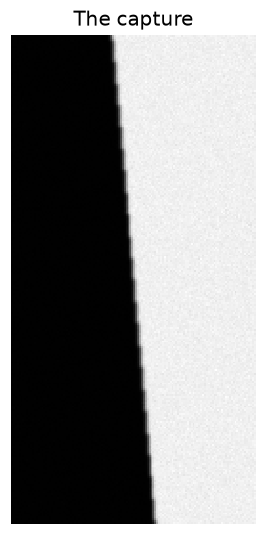

In [2]:
SIGMA = 1.0          # point spread function width, in pixels

def analytic_mtf50(sigma):
    return np.sqrt(np.log(2) / (2 * np.pi ** 2 * sigma ** 2))


def capture_edge(sigma=SIGMA, angle_deg=5.0, h=256, w=128, exposure=0.55, seed=0, noisy=True):
    """A monochrome slanted-edge capture, returned in linear light."""
    scene = psu.slanted_edge(h, w, angle_deg=angle_deg)
    blurred = cv2.GaussianBlur(scene, (0, 0), sigmaX=sigma, sigmaY=sigma)
    if not noisy:
        return blurred
    raw = psu.expose_and_digitize(blurred, np.random.default_rng(seed), exposure=exposure)
    return (raw.astype(float) - psu.BLACK_LEVEL) / (psu.WHITE_LEVEL - psu.BLACK_LEVEL)


roi = capture_edge()
print(f"ROI {roi.shape[1]} x {roi.shape[0]} px, linear light, range {roi.min():.3f} to {roi.max():.3f}")
print(f"We should measure MTF50 = {analytic_mtf50(SIGMA):.4f} cycles per pixel")

plt.figure(figsize=(3.2, 5))
plt.imshow(roi, cmap="gray"); plt.title("The capture"); plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Find the edge in every row

The edge is at a different sub-pixel position in each row. That is what the tilt is for.

Take the centroid of $|\mathrm{d}I/\mathrm{d}x|$, but **only inside a window** around a coarse
estimate. We will see in section 5 what happens without the window.

In [ ]:
def edge_centroids(roi, window=8.0, smooth=1.5):
    """Sub-pixel edge position per row, from a windowed derivative centroid."""
    roi = np.asarray(roi, dtype=float)

    # Coarse location from a smoothed copy. Smoothing locates the edge; it never
    # touches the data we build the edge spread function from.
    smoothed = cv2.GaussianBlur(roi, (0, 0), sigmaX=smooth, sigmaY=0.01)
    coarse = np.argmax(np.abs(np.diff(smoothed, axis=1)), axis=1) + 0.5

    deriv = np.abs(np.diff(roi, axis=1))
    x = np.arange(deriv.shape[1]) + 0.5
    weight = np.where(np.abs(x[None, :] - coarse[:, None]) <= window, deriv, 0.0)

    total = weight.sum(axis=1)
    good = total > 1e-9
    centers = np.full(roi.shape[0], np.nan)
    centers[good] = (weight[good] * x).sum(axis=1) / total[good]
    return centers


centers = edge_centroids(roi)
rows = np.arange(len(centers))
ok = np.isfinite(centers)
slope, intercept = np.polyfit(rows[ok], centers[ok], 1)

true_slope = np.tan(np.deg2rad(5.0))
print(f"fitted edge slope {slope:+.4f} col/row, true {true_slope:+.4f}")
print(f"residual scatter  {np.std(centers[ok] - (slope * rows[ok] + intercept)):.3f} px")

plt.figure(figsize=(3.4, 5))
plt.imshow(roi, cmap="gray")
plt.plot(centers, rows, ".", ms=2, color=psu.PSU_WARM, label="per-row estimate")
plt.plot(slope * rows + intercept, rows, "-", lw=1.5, color=psu.PSU_BLUE, label="line fit")
plt.legend(fontsize=8); plt.title("Edge location"); plt.axis("off")
plt.tight_layout(); plt.show()

## 3. Project, bin, differentiate, transform

Every pixel gets a signed distance from the fitted edge. Because the rows sample many
sub-pixel phases, binning at a quarter pixel gives a **supersampled** edge spread function.

In [ ]:
def slanted_edge_mtf(roi, bin_width=0.25, window=8.0):
    """Returns (freq in cycles/px, mtf, esf_x, esf)."""
    roi = np.asarray(roi, dtype=float)
    rows = np.arange(roi.shape[0])

    centers = edge_centroids(roi, window=window)
    ok = np.isfinite(centers)
    slope, intercept = np.polyfit(rows[ok], centers[ok], 1)
    fitted = slope * rows + intercept

    cols = np.arange(roi.shape[1])
    distance = (cols[None, :] - fitted[:, None]).ravel()
    values = roi.ravel()

    edges = np.arange(distance.min(), distance.max() + bin_width, bin_width)
    idx = np.clip(np.digitize(distance, edges) - 1, 0, len(edges) - 2)
    total = np.bincount(idx, weights=values, minlength=len(edges) - 1)
    count = np.bincount(idx, minlength=len(edges) - 1)
    keep = count > 0
    esf = total[keep] / count[keep]
    esf_x = (edges[:-1] + bin_width / 2)[keep]

    lsf = np.gradient(esf, esf_x)
    lsf = lsf - np.median(np.concatenate([lsf[:5], lsf[-5:]]))
    lsf = lsf * np.hanning(len(lsf))

    spectrum = np.abs(np.fft.rfft(lsf))
    return np.fft.rfftfreq(len(lsf), d=bin_width), spectrum / spectrum[0], esf_x, esf


def mtf50(freq, mtf):
    below = np.where(mtf < 0.5)[0]
    if len(below) == 0 or below[0] == 0:
        return np.nan
    i = below[0]
    return float(freq[i - 1] + (mtf[i - 1] - 0.5) * (freq[i] - freq[i - 1]) / (mtf[i - 1] - mtf[i]))


freq, mtf, esf_x, esf = slanted_edge_mtf(roi)
measured = mtf50(freq, mtf)
expected = analytic_mtf50(SIGMA)

print(f"measured MTF50  {measured:.4f} c/px")
print(f"analytic MTF50  {expected:.4f} c/px")
print(f"difference      {abs(measured - expected) / expected * 100:.1f} %")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))

axes[0].plot(esf_x, esf, ".", ms=2.5, color=psu.PSU_BLUE)
axes[0].set_xlim(-8, 8); axes[0].set_title("Edge spread function")
axes[0].set_xlabel("distance from edge (px)")

axes[1].plot(esf_x, np.gradient(esf, esf_x), color=psu.PSU_GREEN, lw=1.5)
axes[1].set_xlim(-8, 8); axes[1].set_title("Line spread function")
axes[1].set_xlabel("distance from edge (px)")

axes[2].plot(freq, mtf, lw=2, color=psu.PSU_FOREST, label="measured")
axes[2].plot(freq, np.exp(-2 * np.pi ** 2 * SIGMA ** 2 * freq ** 2), "--", lw=1.5,
             color=psu.PSU_WARM, label="analytic")
axes[2].axhline(0.5, color=psu.PSU_GRAY, ls=":")
axes[2].axvline(0.5, color="#555555", ls="--", lw=1.2)
axes[2].text(0.51, 0.9, "Nyquist", fontsize=8.5, color="#555555")
axes[2].set_xlim(0, 0.75); axes[2].set_ylim(0, 1.05)
axes[2].set_xlabel("cycles per pixel"); axes[2].set_title("MTF")
axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 4. One capture is not a measurement

Repeat the whole thing on independent captures of the same target and look at the spread.

In [ ]:
values = np.array([mtf50(*slanted_edge_mtf(capture_edge(seed=s))[:2]) for s in range(40)])
print(f"MTF50 over 40 captures: {values.mean():.4f} +/- {values.std(ddof=1):.4f} c/px")
print(f"analytic:               {expected:.4f} c/px")
print(f"bias: {(values.mean() - expected) / expected * 100:+.1f} %, "
      f"which is inside one standard deviation")

plt.figure(figsize=(6.5, 2.8))
plt.hist(values, bins=12, color=psu.PSU_GREEN, edgecolor="white")
plt.axvline(expected, color=psu.PSU_WARM, lw=2, label="analytic truth")
plt.axvline(values.mean(), color=psu.PSU_FOREST, lw=2, label="measured mean")
plt.xlabel("MTF50 (c/px)"); plt.ylabel("captures"); plt.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 5. Now break it

Take the centroid over the **whole row** instead of a window around the edge. Noise
everywhere contributes weight, so the centroid drifts toward the row center and the fitted
edge slope comes out too shallow. The projection then smears the edge profile.

Watch what the number does, and note that nothing raises an error.

In [ ]:
def edge_centroids_broken(roi):
    """The tempting one-liner. Correct on noise-free data, wrong on real data."""
    deriv = np.abs(np.diff(np.asarray(roi, dtype=float), axis=1))
    x = np.arange(deriv.shape[1]) + 0.5
    return (deriv * x).sum(axis=1) / deriv.sum(axis=1)


def mtf50_broken(roi, bin_width=0.25):
    rows = np.arange(roi.shape[0])
    centers = edge_centroids_broken(roi)
    slope, intercept = np.polyfit(rows, centers, 1)
    fitted = slope * rows + intercept
    cols = np.arange(roi.shape[1])
    distance = (cols[None, :] - fitted[:, None]).ravel()
    edges = np.arange(distance.min(), distance.max() + bin_width, bin_width)
    idx = np.clip(np.digitize(distance, edges) - 1, 0, len(edges) - 2)
    total = np.bincount(idx, weights=roi.ravel(), minlength=len(edges) - 1)
    count = np.bincount(idx, minlength=len(edges) - 1)
    keep = count > 0
    esf = total[keep] / count[keep]
    esf_x = (edges[:-1] + bin_width / 2)[keep]
    lsf = np.gradient(esf, esf_x)
    lsf = (lsf - np.median(np.concatenate([lsf[:5], lsf[-5:]]))) * np.hanning(len(lsf))
    spec = np.abs(np.fft.rfft(lsf))
    return mtf50(np.fft.rfftfreq(len(lsf), d=bin_width), spec / spec[0]), slope


clean = capture_edge(noisy=False)
bad_noisy, slope_noisy = mtf50_broken(roi)
bad_clean, slope_clean = mtf50_broken(clean)

print(f"true edge slope            {true_slope:+.4f} col/row")
print(f"broken slope, clean data   {slope_clean:+.4f}   MTF50 {bad_clean:.4f}")
print(f"broken slope, real capture {slope_noisy:+.4f}   MTF50 {bad_noisy:.4f}")
print(f"windowed, real capture     {slope:+.4f}   MTF50 {measured:.4f}")
print()
print(f"The broken estimator reports a lens {expected / bad_noisy:.1f} times softer than it is.")
print("It passed on clean test data. It failed on a real capture. It never complained.")

## 6. Your own photograph

Print or display a black-to-white edge, tilt it a few degrees, fill the frame, shoot raw.
Drop it in `Images/` and run this.

Two things to get right, both of which the slides warn about: work in **linear light**, and
use a **single channel** so you are not measuring the demosaic interpolator as well.

In [ ]:
raws = psu.find_raw_files()

if not raws:
    print("No raw file found under an Images/ folder.")
    print("The simulation above stands on its own; this cell is for your own capture.")
else:
    import rawpy
    path = raws[0]
    with rawpy.imread(str(path)) as raw:
        bayer = raw.raw_image_visible.astype(float)
        black = float(np.mean(raw.black_level_per_channel))
        white = float(raw.white_level)

    # One green plane. Green is on (0,1) and (1,0) of an RGGB tile; take (0,1).
    green = (bayer[0::2, 1::2] - black) / (white - black)
    print(f"{path.name}: green plane {green.shape[1]} x {green.shape[0]}")
    print("Set ROI_Y, ROI_X, and ROI_H, ROI_W to a region containing your slanted edge.")

    ROI_Y, ROI_X, ROI_H, ROI_W = 0, 0, min(256, green.shape[0]), min(128, green.shape[1])
    sub = green[ROI_Y:ROI_Y + ROI_H, ROI_X:ROI_X + ROI_W]

    f, m, _, _ = slanted_edge_mtf(sub)
    print(f"MTF50 = {mtf50(f, m):.4f} cycles per pixel (on the green plane, so per green sample)")

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    axes[0].imshow(sub, cmap="gray"); axes[0].set_title("ROI"); axes[0].axis("off")
    axes[1].plot(f, m, lw=2, color=psu.PSU_FOREST); axes[1].axhline(0.5, ls=":", color=psu.PSU_GRAY)
    axes[1].set_xlim(0, 0.75); axes[1].set_ylim(0, 1.05)
    axes[1].set_xlabel("cycles per pixel"); axes[1].set_title("MTF")
    plt.tight_layout(); plt.show()

## Back to the slides

Three things to land:

1. The method is six steps and about forty lines. They can write it.
2. It was checked against an answer we could predict. That is what makes it a measurement.
3. The broken version returned a plausible number. **Plausible is not correct**, and the only
   defense is a case where you already know the answer.

Next: Project 1 deliverables, then lecture 5 derives the noise that set the spread in section 4.